In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    '/content/Datheon_Task3_Customer_Churn_Classification.csv'
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [3]:
# Make a copy of the dataset
df = df.copy()

# Remove the customer ID because it is not a useful predictive feature
df.drop(columns=['customerID'], inplace=True)

# Convert TotalCharges to numeric
# Blank or invalid entries become missing values
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce'
)

# Fill missing TotalCharges with the median
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

# Check the cleaned dataset
print("Dataset shape:", df.shape)
print("\nMissing values remaining:", df.isnull().sum().sum())
print("\nTotalCharges data type:", df['TotalCharges'].dtype)
print("\nChurn distribution:")
print(df['Churn'].value_counts())

Dataset shape: (7043, 20)

Missing values remaining: 0

TotalCharges data type: float64

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

# Convert categorical features into numerical columns
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=['object']).columns,
    drop_first=True,
    dtype=int
)

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts())

print("\nTesting churn distribution:")
print(y_test.value_counts())

print("\nTarget mapping: No = 0, Yes = 1")


Training features: (5634, 30)
Testing features: (1409, 30)

Training churn distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing churn distribution:
Churn
0    1035
1     374
Name: count, dtype: int64

Target mapping: No = 0, Yes = 1


In [5]:
# Install XGBoost if needed
%pip -q install xgboost

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Calculate class imbalance ratio using training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

# Random Forest with balanced class weights
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# XGBoost with class imbalance adjustment
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Train both models
rf_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

xgb_model.fit(X_train, y_train)
print("XGBoost trained successfully!")

print("\nClass imbalance ratio:", round(scale_pos_weight, 2))
print("Both models are trained.")

Random Forest trained successfully!
XGBoost trained successfully!

Class imbalance ratio: 2.77
Both models are trained.



Random Forest - Classification Report
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



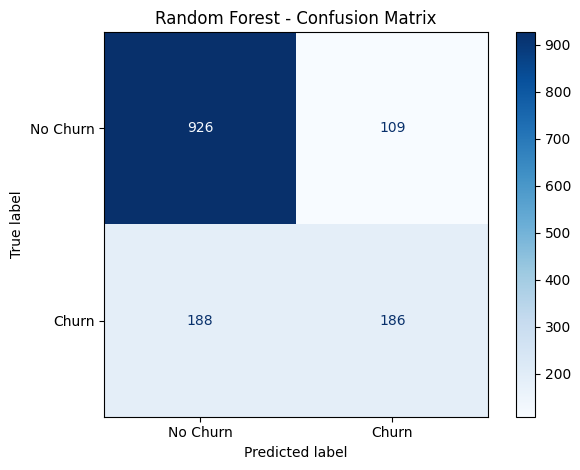


XGBoost - Classification Report
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.81      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



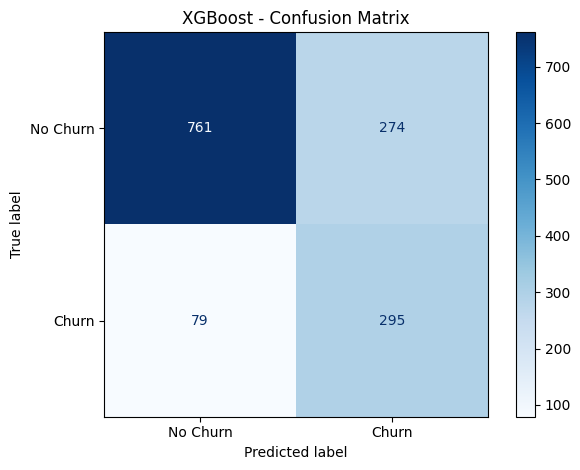


Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,XGBoost,0.7495,0.5185,0.7888,0.6257,0.8416
0,Random Forest,0.7892,0.6305,0.4973,0.5561,0.8246


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name} - Classification Report")
    print(classification_report(
        y_test, y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["No Churn", "Churn"],
        cmap="Blues"
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

print("\nModel Comparison:")
display(results_df.round(4))

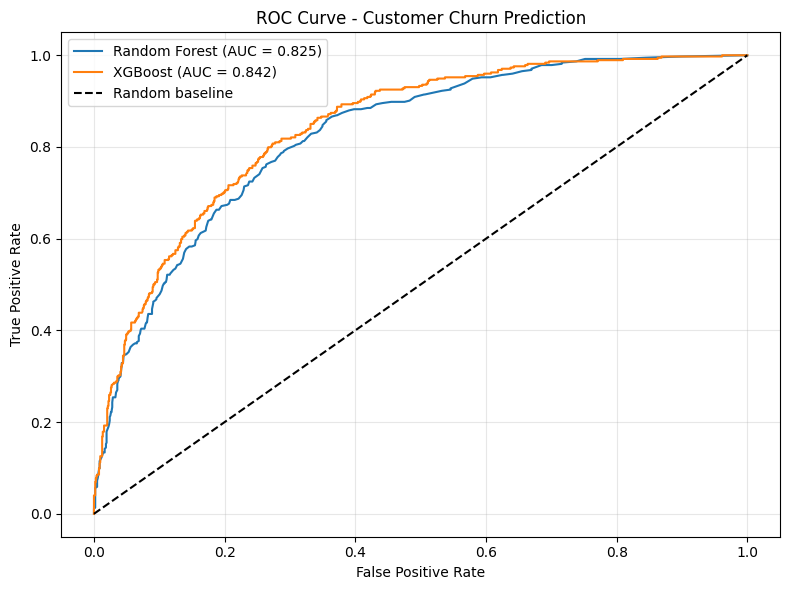

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random baseline')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

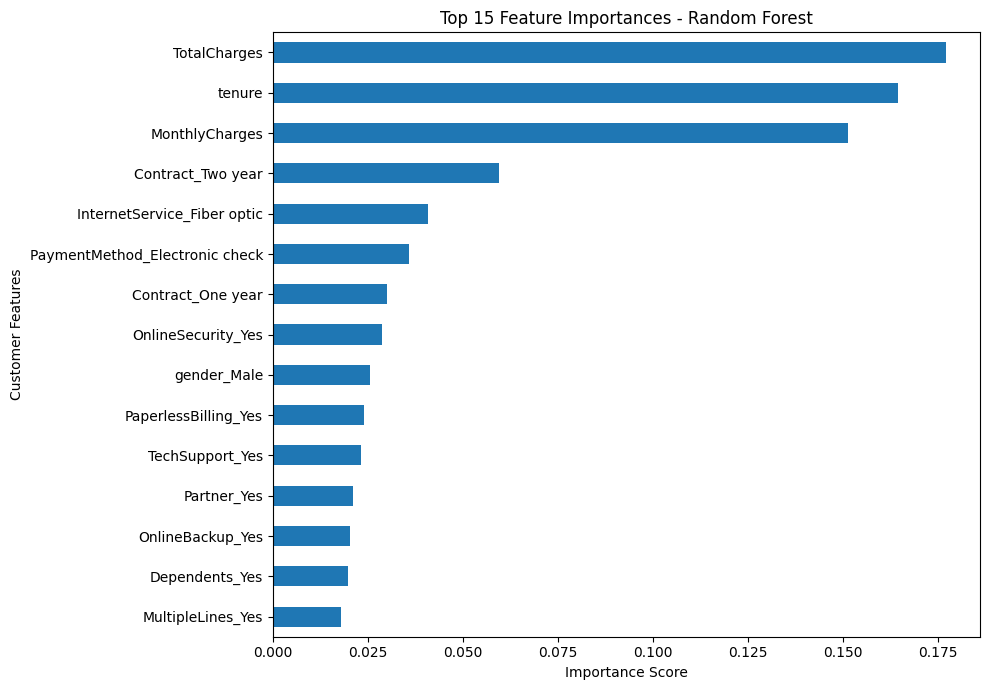

Top 10 important features:


,Importance
TotalCharges,0.177273
tenure,0.164566
MonthlyCharges,0.151406
Contract_Two year,0.059623
InternetService_Fiber optic,0.040754
PaymentMethod_Electronic check,0.035761
Contract_One year,0.029983
OnlineSecurity_Yes,0.028859
gender_Male,0.025542
PaperlessBilling_Yes,0.023940


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Display the top 15 features
top_features = importance.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_features.plot(kind='barh')
plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Customer Features')
plt.tight_layout()
plt.show()

print("Top 10 important features:")
display(importance.head(10).to_frame("Importance"))

In [9]:
# Compare models by ROC-AUC
results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.loc[0, "Model"]

if best_model_name == "Random Forest":
    best_model = rf_model
else:
    best_model = xgb_model

best_auc = results_df.loc[0, "ROC-AUC"]

print("Best model by ROC-AUC:", best_model_name)
print("ROC-AUC:", round(best_auc, 4))

if best_auc > 0.80:
    print("The model meets the ROC-AUC target above 0.80.")
else:
    print("The model has not yet reached the ROC-AUC target above 0.80.")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7495,0.5185,0.7888,0.6257,0.8416
1,Random Forest,0.7892,0.6305,0.4973,0.5561,0.8246


Best model by ROC-AUC: XGBoost
ROC-AUC: 0.8416
The model meets the ROC-AUC target above 0.80.


In [10]:
print("PROJECT CONCLUSION")
print("------------------")
print("The telecom customer churn dataset was cleaned and analyzed.")
print("Categorical variables were converted into numerical features.")
print("The data was split into training and testing sets.")
print("Random Forest and XGBoost classifiers were trained.")
print("Class imbalance was addressed using class weighting.")
print("Models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.")
print("Confusion matrices, ROC curves, and feature importance were visualized.")
print(f"Best model by ROC-AUC: {best_model_name}")
print(f"Test ROC-AUC: {best_auc:.4f}")

PROJECT CONCLUSION
------------------
The telecom customer churn dataset was cleaned and analyzed.
Categorical variables were converted into numerical features.
The data was split into training and testing sets.
Random Forest and XGBoost classifiers were trained.
Class imbalance was addressed using class weighting.
Models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.
Confusion matrices, ROC curves, and feature importance were visualized.
Best model by ROC-AUC: XGBoost
Test ROC-AUC: 0.8416
